# Quasi-steady state approximation of two-species model

This notebook studies a fraction-QSS reduction of `analysis_full_ecoevo_2sp.ipynb`.

The full model now assumes that a free female starts childcare at a constant per-capita rate $\alpha_i$ whenever males are present. The male type involved in childcare is chosen randomly from the current male frequencies. In the reduced model below, each species has a fixed infanticidal male frequency $p_i$:

$$
q_{N,i}=1-p_i,\qquad q_{I,i}=p_i.
$$

The sex ratio is approximated by the invariant manifold

$$
F_i=M_i=N_i/2,
$$

and the QSS approximation is imposed on female reproductive-state fractions, not on absolute female densities. For species $i$,

$$
F_i=F_{f,i}+C_{1,N,i}+C_{2,N,i}+C_{1,I,i}+C_{2,I,i},
$$

with

$$
x_{0,i}=\frac{F_{f,i}}{F_i},\quad
x_{1N,i}=\frac{C_{1,N,i}}{F_i},\quad
x_{2N,i}=\frac{C_{2,N,i}}{F_i},\quad
x_{1I,i}=\frac{C_{1,I,i}}{F_i},\quad
x_{2I,i}=\frac{C_{2,I,i}}{F_i}.
$$

The fractions satisfy

$$
x_{0,i}+x_{1N,i}+x_{2N,i}+x_{1I,i}+x_{2I,i}=1.
$$

Let

$$
h_i(N_i,p_i)=\gamma_i p_i N_i/2,\qquad
b_{I,i}=(1-s_i)b_{N,i},
$$

and

$$
b_i=\beta_i\left(b_{N,i}x_{2N,i}+b_{I,i}x_{2I,i}\right).
$$

The fraction-QSS equations are

$$
\begin{aligned}
\dot{x}_{0,i} &=
-\alpha_i x_{0,i}
+(1+b_{N,i})\beta_i x_{2N,i}
+(1+b_{I,i})\beta_i x_{2I,i}
-b_i x_{0,i},\\
\dot{x}_{1N,i} &=
\alpha_i(1-p_i)x_{0,i}
-(\beta_i+h_i+b_i)x_{1N,i},\\
\dot{x}_{2N,i} &=
\beta_i x_{1N,i}
-(\beta_i+h_i+b_i)x_{2N,i},\\
\dot{x}_{1I,i} &=
\alpha_i p_i x_{0,i}
+h_i(x_{1N,i}+x_{2N,i}+x_{2I,i})
-(\beta_i+b_i)x_{1I,i},\\
\dot{x}_{2I,i} &=
\beta_i x_{1I,i}
-(\beta_i+h_i+b_i)x_{2I,i}.
\end{aligned}
$$

The reduced density dynamics are

$$
\dot N_i=N_i\left[
\beta_i\left(b_{N,i}x_{2N,i}^*+b_{I,i}x_{2I,i}^*\right)
-d_i(N_i+\rho_{ij}N_j)
\right].
$$


Numerical domain: $\alpha_i,\gamma_i,b_{N,i}\geq0$, $\beta_i,d_i>0$,
$s_i,p_i\in[0,1]$, and $\rho_{ij}\geq0$. Invalid inputs or failed QSS
self-consistency checks raise an error instead of substituting an approximate solution.
Equilibrium searches use model-based density bounds, independently of the plot limits.
Boundary stability uses derivatives within the nonnegative density domain;
nonhyperbolic equilibria are distinguished from unstable equilibria.


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, root


# =========================
# Parameters
# =========================
params = {
    'alpha1': 1.0,
    'beta1': 1.0,
    'gamma1': 0.01,
    'd1': 0.001,
    'b_N1': 1.2,
    's1': 0.1,
    'p1': 0.0,

    'alpha2': 1.0,
    'beta2': 1.0,
    'gamma2': 0.01,
    'd2': 0.001,
    'b_N2': 1.0,
    's2': 0.1,
    'p2': 0.8,

    'rho12': 1.0,
    'rho21': 1.0,
}

plot_config = {
    'N1_min': 0.0,
    'N1_max': 350.0,
    'N2_min': 0.0,
    'N2_max': 350.0,
    'auto_margin': 3.5,
    'fallback_max': 500.0,
    'eps': 1e-6,
}


def validate_species_parameters(alpha, beta, gamma, b_N, s, p_self):
    values = np.asarray([alpha, beta, gamma, b_N, s, p_self], dtype=float)
    if not np.all(np.isfinite(values)):
        raise ValueError('Species parameters must be finite.')
    if alpha < 0.0 or beta <= 0.0 or gamma < 0.0 or b_N < 0.0:
        raise ValueError('Require alpha >= 0, beta > 0, gamma >= 0, b_N >= 0.')
    if not (0.0 <= s <= 1.0 and 0.0 <= p_self <= 1.0):
        raise ValueError('Require 0 <= s <= 1 and 0 <= p_self <= 1.')


def b_I_from_cost(b_N, s):
    return (1.0 - s) * b_N


def _qss_fractions_from_birth_rate(alpha, beta, h, p_self, birth_rate):
    A = beta + h + birth_rate
    x1N_per_x0 = alpha * (1.0 - p_self) / A
    x2N_per_x0 = beta * x1N_per_x0 / A

    # Algebraically equal to beta + birth_rate - h*beta/A,
    # without subtracting nearly equal numbers for large h.
    denom_I = ((beta + birth_rate)**2 + h * birth_rate) / A
    numer_I_per_x0 = alpha * p_self + h * (x1N_per_x0 + x2N_per_x0)
    x1I_per_x0 = numer_I_per_x0 / denom_I
    x2I_per_x0 = beta * x1I_per_x0 / A

    weights = np.array([1.0, x1N_per_x0, x2N_per_x0, x1I_per_x0, x2I_per_x0])
    return weights / np.sum(weights)


def _qss_fractions_scalar(N, alpha, beta, gamma, b_N, s, p_self):
    """Solve the QSS self-consistency equation for validated scalar inputs."""
    b_I = b_I_from_cost(b_N, s)
    h = 0.5 * gamma * p_self * float(N)
    upper = beta * max(b_N, b_I)

    def residual(birth_rate):
        fractions = _qss_fractions_from_birth_rate(alpha, beta, h, p_self, birth_rate)
        return beta * (b_N * fractions[2] + b_I * fractions[4]) - birth_rate

    f0 = residual(0.0)
    if f0 == 0.0:
        birth_rate = 0.0
    else:
        f_upper = residual(upper)
        if not (np.isfinite(f0) and np.isfinite(f_upper) and f0 > 0.0 and f_upper <= 0.0):
            raise RuntimeError(f'Cannot bracket QSS birth rate at N={N}, p={p_self}.')
        birth_rate = float(brentq(residual, 0.0, upper, xtol=1e-12, rtol=1e-12, maxiter=100))

    fractions = _qss_fractions_from_birth_rate(alpha, beta, h, p_self, birth_rate)
    if (not np.all(np.isfinite(fractions)) or np.any(fractions < 0.0)
            or abs(np.sum(fractions) - 1.0) > 1e-12
            or abs(residual(birth_rate)) > 1e-10 * max(1.0, upper)):
        raise RuntimeError(f'Invalid QSS solution at N={N}, p={p_self}.')
    return fractions


def qss_fractions(N, alpha, beta, gamma, b_N, s, p_self):
    """QSS fractions, with state index first for array-valued densities."""
    validate_species_parameters(alpha, beta, gamma, b_N, s, p_self)
    N_arr = np.asarray(N, dtype=float)
    if not np.all(np.isfinite(N_arr)) or np.any(N_arr < 0.0):
        raise ValueError('Density must be finite and nonnegative.')
    if N_arr.ndim == 0:
        return _qss_fractions_scalar(N_arr, alpha, beta, gamma, b_N, s, p_self)

    out = np.empty((5,) + N_arr.shape, dtype=float)
    for index in np.ndindex(N_arr.shape):
        out[(slice(None),) + index] = _qss_fractions_scalar(
            N_arr[index], alpha, beta, gamma, b_N, s, p_self
        )
    return out


def qss_birth_rate(N, alpha, beta, gamma, b_N, s, p_self):
    x0, x1N, x2N, x1I, x2I = qss_fractions(N, alpha, beta, gamma, b_N, s, p_self)
    b_I = b_I_from_cost(b_N, s)
    return beta * (b_N * x2N + b_I * x2I)


def species_H(alpha, beta, gamma, d, b_N, s, p_self, rho, N_self, N_other):
    birth_rate = qss_birth_rate(N_self, alpha, beta, gamma, b_N, s, p_self)
    comp = d * (N_self + rho * N_other)
    return birth_rate - comp


def H1(N1, N2, p):
    return species_H(
        p['alpha1'], p['beta1'], p['gamma1'], p['d1'],
        p['b_N1'], p['s1'], p['p1'], p['rho12'], N1, N2
    )


def H2(N1, N2, p):
    return species_H(
        p['alpha2'], p['beta2'], p['gamma2'], p['d2'],
        p['b_N2'], p['s2'], p['p2'], p['rho21'], N2, N1
    )


def dN1_dt(N1, N2, p):
    return N1 * H1(N1, N2, p)


def dN2_dt(N1, N2, p):
    return N2 * H2(N1, N2, p)


def reduced_rhs(time, y, p):
    N1, N2 = np.maximum(np.asarray(y, dtype=float), 0.0)
    return np.array([dN1_dt(N1, N2, p), dN2_dt(N1, N2, p)], dtype=float)


def single_species_equilibrium(alpha, beta, gamma, d, b_N, s, p_self):
    validate_species_parameters(alpha, beta, gamma, b_N, s, p_self)
    if not np.isfinite(d) or d <= 0.0:
        raise ValueError('Require a finite density-dependent mortality d > 0.')

    def f(N):
        return qss_birth_rate(N, alpha, beta, gamma, b_N, s, p_self) - d * N

    if f(0.0) == 0.0:
        return None
    upper = beta * max(b_N, b_I_from_cost(b_N, s)) / d
    return float(brentq(f, 0.0, upper, xtol=1e-11, rtol=1e-11, maxiter=200))


def resolve_plot_limits(N1_single, N2_single, cfg):
    N1_auto = cfg['fallback_max'] if N1_single is None else cfg['auto_margin'] * N1_single
    N2_auto = cfg['fallback_max'] if N2_single is None else cfg['auto_margin'] * N2_single
    N1_max = N1_auto if cfg['N1_max'] is None else cfg['N1_max']
    N2_max = N2_auto if cfg['N2_max'] is None else cfg['N2_max']
    return cfg['N1_min'], float(N1_max), cfg['N2_min'], float(N2_max)


def numerical_jacobian(func, x, rel_step=1e-6, abs_step=1e-7):
    """Differentiate on the nonnegative domain; use a forward difference at its boundary."""
    x = np.asarray(x, dtype=float)
    f0 = np.asarray(func(x), dtype=float)
    J = np.empty((f0.size, x.size), dtype=float)
    for k in range(x.size):
        h = max(abs_step, rel_step * max(1.0, abs(x[k])))
        xp = x.copy()
        xp[k] += h
        if x[k] < h:
            xpp = x.copy()
            xpp[k] += 2.0 * h
            J[:, k] = (-3.0 * f0 + 4.0 * np.asarray(func(xp)) - np.asarray(func(xpp))) / (2.0 * h)
        else:
            xm = x.copy()
            xm[k] -= h
            J[:, k] = (np.asarray(func(xp)) - np.asarray(func(xm))) / (2.0 * h)
    return J


def jacobian(N1, N2, p):
    return numerical_jacobian(lambda z: reduced_rhs(0.0, z, p), np.array([N1, N2], dtype=float))


def origin_linear_terms(p):
    return np.array([
        [qss_birth_rate(0.0, p['alpha1'], p['beta1'], p['gamma1'], p['b_N1'], p['s1'], p['p1']), 0.0],
        [0.0, qss_birth_rate(0.0, p['alpha2'], p['beta2'], p['gamma2'], p['b_N2'], p['s2'], p['p2'])],
    ], dtype=float)


def classify_equilibrium(N1, N2, p, tol=1e-8):
    if abs(N1) <= tol and abs(N2) <= tol:
        origin_terms = origin_linear_terms(p)
        is_stable = bool(origin_terms[0, 0] < -tol and origin_terms[1, 1] < -tol)
        return is_stable, np.array([origin_terms[0, 0], origin_terms[1, 1]], dtype=float)
    eigvals = np.linalg.eigvals(jacobian(N1, N2, p))
    return bool(np.max(np.real(eigvals)) < -tol), eigvals


def _append_unique_equilibrium(equilibria, point, p, tol=1e-6):
    point = np.maximum(np.asarray(point, dtype=float), 0.0)
    if any(np.linalg.norm(point - eq['point']) <= tol for eq in equilibria):
        return
    stable, eigvals = classify_equilibrium(point[0], point[1], p)
    status = 'stable' if stable else ('unstable' if np.max(np.real(eigvals)) > 1e-8 else 'nonhyperbolic')
    equilibria.append({'point': point, 'stable': stable, 'status': status, 'eigenvalues': eigvals})


def equilibrium_search_bounds(p):
    # At an equilibrium, d_i*N_i <= birth_rate_i <= beta_i*max(b_Ni, b_Ii).
    # These model bounds are independent of the chosen plotting window.
    maxima = []
    for i in (1, 2):
        validate_species_parameters(*(p[f'{key}{i}'] for key in ('alpha', 'beta', 'gamma', 'b_N', 's', 'p')))
        d = p[f'd{i}']
        if not np.isfinite(d) or d <= 0.0:
            raise ValueError('Require finite d1 > 0 and d2 > 0.')
        b_N = p[f'b_N{i}']
        b_I = b_I_from_cost(b_N, p[f's{i}'])
        maxima.append(max(1e-6, p[f'beta{i}'] * max(b_N, b_I) / d) * (1.0 + 1e-8))
    if not all(np.isfinite(p[key]) and p[key] >= 0.0 for key in ('rho12', 'rho21')):
        raise ValueError('Require finite, nonnegative competition coefficients.')
    return 0.0, maxima[0], 0.0, maxima[1]


def find_equilibria(p):
    """Find boundary and interior equilibria using model bounds and multiple seeds.

    A finite seed search is not a mathematical guarantee of completeness.
    """
    N1_min, N1_max, N2_min, N2_max = equilibrium_search_bounds(p)
    equilibria = []
    _append_unique_equilibrium(equilibria, [0.0, 0.0], p)

    N1_single = single_species_equilibrium(
        p['alpha1'], p['beta1'], p['gamma1'], p['d1'], p['b_N1'], p['s1'], p['p1']
    )
    N2_single = single_species_equilibrium(
        p['alpha2'], p['beta2'], p['gamma2'], p['d2'], p['b_N2'], p['s2'], p['p2']
    )
    if N1_single is not None and N1_min - 1e-8 <= N1_single <= N1_max + 1e-8:
        _append_unique_equilibrium(equilibria, [N1_single, 0.0], p)
    if N2_single is not None and N2_min - 1e-8 <= N2_single <= N2_max + 1e-8:
        _append_unique_equilibrium(equilibria, [0.0, N2_single], p)

    seeds = []
    for x in np.linspace(max(1e-6, N1_min), N1_max, 9):
        for y in np.linspace(max(1e-6, N2_min), N2_max, 9):
            seeds.append([x, y])
    if N1_single is not None and N2_single is not None:
        seeds.extend([
            [0.5 * N1_single, 0.5 * N2_single],
            [N1_single, N2_single],
            [0.25 * N1_single, N2_single],
            [N1_single, 0.25 * N2_single],
        ])

    def F(z):
        z = np.maximum(np.asarray(z, dtype=float), 0.0)
        return np.array([H1(z[0], z[1], p), H2(z[0], z[1], p)], dtype=float)

    # Linearized nullcline intersections seed coexistence close to either axis.
    # A uniform grid alone can miss these very small invading populations.
    boundary_points = []
    if N1_single is not None:
        boundary_points.append(np.array([N1_single, 0.0]))
    if N2_single is not None:
        boundary_points.append(np.array([0.0, N2_single]))
    for boundary in boundary_points:
        try:
            candidate = boundary - np.linalg.solve(numerical_jacobian(F, boundary), F(boundary))
        except np.linalg.LinAlgError:
            continue
        if np.all(np.isfinite(candidate)) and np.all(candidate > 0.0):
            seeds.insert(0, candidate)

    for seed in seeds:
        sol = root(F, np.asarray(seed, dtype=float), method='hybr', options={'xtol': 1e-11})
        # Accept only verified roots, including a stagnation report at a valid root.
        point = np.asarray(sol.x, dtype=float)
        if np.any(point < 0.0) or not np.all(np.isfinite(point)):
            continue
        if not (N1_min - 1e-7 <= point[0] <= N1_max + 1e-7 and N2_min - 1e-7 <= point[1] <= N2_max + 1e-7):
            continue
        if np.linalg.norm(F(point), ord=np.inf) > 1e-11:
            continue
        _append_unique_equilibrium(equilibria, point, p)

    equilibria.sort(key=lambda eq: (eq['point'][0] <= 1e-8, eq['point'][1] <= 1e-8, eq['point'][0], eq['point'][1]))
    return equilibria


### Phase plane and nullclines

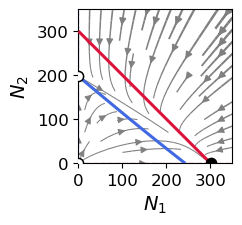

Equilibria:
[300.59144685   0.        ] stable
[  0.         198.12541393] unstable
[0. 0.] unstable


In [8]:
phase_plane_style = {
    'figsize': (2.0, 2.0),
    'n_grid': 220,
    'stream_density': 0.5,
    'stream_arrowsize': 1.0,
    'nullcline_lw': 2.2,
    'equilibrium_s': 54,
    'save_svg': True,
    'svg_path': 'phase_plane.svg',
    'equal_aspect': True,
    'show_legend': False,
}

N1_single = single_species_equilibrium(params['alpha1'], params['beta1'], params['gamma1'], params['d1'], params['b_N1'], params['s1'], params['p1'])
N2_single = single_species_equilibrium(params['alpha2'], params['beta2'], params['gamma2'], params['d2'], params['b_N2'], params['s2'], params['p2'])
N1_min, N1_max, N2_min, N2_max = resolve_plot_limits(N1_single, N2_single, plot_config)

eps = plot_config['eps']
N1_vals = np.linspace(max(eps, N1_min), N1_max, phase_plane_style['n_grid'])
N2_vals = np.linspace(max(eps, N2_min), N2_max, phase_plane_style['n_grid'])
N1_grid, N2_grid = np.meshgrid(N1_vals, N2_vals)

# Each species' QSS birth rate depends only on its own density.
B1 = qss_birth_rate(N1_vals, params['alpha1'], params['beta1'], params['gamma1'],
                    params['b_N1'], params['s1'], params['p1'])
B2 = qss_birth_rate(N2_vals, params['alpha2'], params['beta2'], params['gamma2'],
                    params['b_N2'], params['s2'], params['p2'])
H1_grid = B1[None, :] - params['d1'] * (N1_grid + params['rho12'] * N2_grid)
H2_grid = B2[:, None] - params['d2'] * (N2_grid + params['rho21'] * N1_grid)
U = N1_grid * H1_grid
V = N2_grid * H2_grid
speed = np.hypot(U, V)
equilibria = find_equilibria(params)

neutral_points = np.array([eq['point'] for eq in equilibria if eq['status'] == 'nonhyperbolic'], dtype=float)
line_width = 0.7 + 1.3 * speed / (np.nanmax(speed) + 1e-14)
fig, ax = plt.subplots(figsize=phase_plane_style['figsize'])
ax.streamplot(
    N1_vals, N2_vals, U, V,
    density=phase_plane_style['stream_density'],
    color='grey',
    linewidth=line_width,
    arrowsize=phase_plane_style['stream_arrowsize'],
    integration_direction='both',
    zorder=1,
)
ax.contour(N1_grid, N2_grid, H1_grid, levels=[0.0], colors=['crimson'], linewidths=phase_plane_style['nullcline_lw'], zorder=3)
ax.contour(N1_grid, N2_grid, H2_grid, levels=[0.0], colors=['royalblue'], linewidths=phase_plane_style['nullcline_lw'], zorder=3)

stable_points = np.array([eq['point'] for eq in equilibria if eq['stable']], dtype=float)
unstable_points = np.array([eq['point'] for eq in equilibria if eq['status'] == 'unstable'], dtype=float)
if stable_points.size:
    ax.scatter(stable_points[:, 0], stable_points[:, 1], s=phase_plane_style['equilibrium_s'], facecolors='black', edgecolors='black', linewidths=1.1, zorder=4)
if unstable_points.size:
    ax.scatter(unstable_points[:, 0], unstable_points[:, 1], s=phase_plane_style['equilibrium_s'], facecolors='white', edgecolors='black', linewidths=1.1, zorder=4)

if neutral_points.size:
    ax.scatter(neutral_points[:, 0], neutral_points[:, 1], s=phase_plane_style['equilibrium_s'], marker='s', facecolors='none', edgecolors='black', zorder=4)

ax.axhline(0.0, color='crimson', linestyle='--', linewidth=1.0, alpha=0.45, zorder=2)
ax.axvline(0.0, color='royalblue', linestyle='--', linewidth=1.0, alpha=0.45, zorder=2)
ax.set_xlim(N1_min, N1_max)
ax.set_ylim(N2_min, N2_max)
ax.set_xticks(np.arange(N1_min, N1_max + 1, 100))
ax.set_yticks(np.arange(N2_min, N2_max + 1, 100))
ax.set_xlabel(r'$N_1$', fontsize=14)
ax.set_ylabel(r'$N_2$', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
if phase_plane_style['equal_aspect']:
    ax.set_aspect('equal', adjustable='box')

if phase_plane_style['show_legend']:
    from matplotlib.lines import Line2D

    handles = [
        Line2D([0], [0], color='crimson', label=r'$\dot N_1=0$'),
        Line2D([0], [0], color='royalblue', label=r'$\dot N_2=0$'),
        Line2D([0], [0], marker='o', linestyle='None', color='black', markerfacecolor='black', label='stable'),
        Line2D([0], [0], marker='o', linestyle='None', color='black', markerfacecolor='white', label='unstable'),
        Line2D([0], [0], marker='s', linestyle='None', color='black', markerfacecolor='white', label='nonhyperbolic'),
    ]
    ax.legend(handles=handles, frameon=True)
if phase_plane_style['save_svg']:
    fig.savefig(phase_plane_style['svg_path'], format='svg', bbox_inches='tight')
plt.show()

print('Equilibria:')
for eq in equilibria:
    print(eq['point'], eq['status'])


### Outcome diagram on the $p_1-p_2$ plane


In [9]:
from tqdm.auto import tqdm

p_plane_config = {
    'n_p1': 100,
    'n_p2': 100,
    'p1_min': 0.0,
    'p1_max': 1.0,
    'p2_min': 0.0,
    'p2_max': 1.0,
}

p1_values = np.linspace(p_plane_config['p1_min'], p_plane_config['p1_max'], p_plane_config['n_p1'])
p2_values = np.linspace(p_plane_config['p2_min'], p_plane_config['p2_max'], p_plane_config['n_p2'])

outcome_labels = [
    'coexistence',
    'both_extinct',
    'species1_extinct',
    'species2_extinct',
    'multistable',
    'unresolved',
]
outcome_to_code = {label: idx for idx, label in enumerate(outcome_labels)}


def classify_p_plane_outcome(equilibria, tol=1e-7):
    stable_equilibria = [eq for eq in equilibria if eq['stable']]
    if not stable_equilibria:
        return 'unresolved'
    if len(stable_equilibria) > 1:
        return 'multistable'

    N1, N2 = stable_equilibria[0]['point']
    if N1 <= tol and N2 <= tol:
        return 'both_extinct'
    if N1 <= tol:
        return 'species1_extinct'
    if N2 <= tol:
        return 'species2_extinct'
    return 'coexistence'


outcome_grid = np.full((p2_values.size, p1_values.size), outcome_to_code['unresolved'], dtype=int)
total_grid_points = p1_values.size * p2_values.size

with tqdm(total=total_grid_points, desc='Scanning p1-p2 plane') as progress:
    for row, p2_value in enumerate(p2_values):
        for col, p1_value in enumerate(p1_values):
            p_scan = dict(params)
            p_scan['p1'] = float(p1_value)
            p_scan['p2'] = float(p2_value)
            equilibria = find_equilibria(p_scan)
            outcome = classify_p_plane_outcome(equilibria)
            outcome_grid[row, col] = outcome_to_code[outcome]
            progress.update(1)

Scanning p1-p2 plane:   0%|          | 0/10000 [00:00<?, ?it/s]

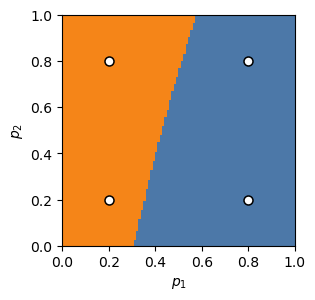

In [12]:
from matplotlib.colors import BoundaryNorm, ListedColormap

p_plane_plot_config = {
    'figure_size': (3.0, 3.0),
    'marker_points': [
        (0.2, 0.2),
        (0.2, 0.8),
        (0.8, 0.8),
        (0.8, 0.2),
    ],
    'marker_size': 42,
}

p_plane_colors = {
    'coexistence': '#4c78a8',
    'both_extinct': '#bab0ac',
    'species1_extinct': '#54a24b',
    'species2_extinct': '#f58518',
    'multistable': '#b279a2',
    'unresolved': '#e45756',
}

cmap = ListedColormap([p_plane_colors[label] for label in outcome_labels])
norm = BoundaryNorm(np.arange(-0.5, len(outcome_labels) + 0.5, 1.0), cmap.N)

def p_axis_extent(values, minimum, maximum):
    if values.size == 1:
        return minimum, maximum
    half_step = 0.5 * (values[1] - values[0])
    return values[0] - half_step, values[-1] + half_step


fig, ax = plt.subplots(figsize=p_plane_plot_config['figure_size'])
ax.imshow(
    outcome_grid,
    origin='lower',
    aspect='auto',
    interpolation='none',
    extent=[
        *p_axis_extent(p1_values, p_plane_config['p1_min'], p_plane_config['p1_max']),
        *p_axis_extent(p2_values, p_plane_config['p2_min'], p_plane_config['p2_max']),
    ],
    cmap=cmap,
    norm=norm,
)

marker_points = np.asarray(p_plane_plot_config['marker_points'], dtype=float)
ax.scatter(
    marker_points[:, 0],
    marker_points[:, 1],
    s=p_plane_plot_config['marker_size'],
    facecolors='white',
    edgecolors='black',
    linewidths=1.1,
    zorder=3,
)

ax.set_xlim(p_plane_config['p1_min'], p_plane_config['p1_max'])
ax.set_ylim(p_plane_config['p2_min'], p_plane_config['p2_max'])
ax.set_xlabel(r'$p_1$')
ax.set_ylabel(r'$p_2$')

plt.show()